# Lab 5: Backpropagation

In Lab 4, the gradient of every function used in a descent run was derived and coded by hand, and a numerical derivative was used to check it. A neural network is a chain of many such functions, and training it requires the gradient of the final loss with respect to the parameters of every one of them. Backpropagation obtains these gradients by applying the chain rule one function at a time, from the loss back to the input, so each function only needs its own forward and backward code.

In this lab:

1. **Part 1:** split the single neuron from Lab 4 into three functions, each with a forward and a backward, and train it with them.
2. **Part 2:** turn these functions into minitorch modules.
3. **Part 3:** chain modules in a `Sequential` and check the gradients of a whole network.
4. **Part 4:** write the optimizer.
5. **Part 5:** train a network on XOR and find out when training does not converge.
6. **Part 6:** look at two common causes of failed training: initialization and the order of calls.

Every backward written in this lab is checked against `numerical_gradient`.

In [1]:
import sys
sys.path.append('../')
import warnings
warnings.filterwarnings("ignore")

%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

import minitorch
from minitorch.layer import Linear, Sigmoid, Sequential
from minitorch.loss import MSELoss
from minitorch.optim import SGD
from tests import lab05_checks as checks

## Part 1: Backpropagation on a single neuron

A single neuron computes

$$\mathbf{Z} = \mathbf{X}\mathbf{W}^\top + \mathbf{b}, \qquad \mathbf{A} = \sigma(\mathbf{Z}), \qquad L = \operatorname{mean}\big((\mathbf{A} - \mathbf{Y})^2\big),$$

where $\mathbf{b}$ is added to every row of $\mathbf{X}\mathbf{W}^\top$ and $\mathbf{Y}$ holds the targets. 

> **Note: this differs from the course.** In the course, a linear layer is written $\mathbf{W}^\top\mathbf{X} - \mathbf{b}$. The code in this lab, and in the rest of minitorch, uses $\mathbf{X}\mathbf{W}^\top + \mathbf{b}$. This is equivalent to the course notation, and is done mainly to match PyTorch's implementation and save us trouble later.
>
> - **Multiplication order.** Arrays hold one example per row, with shape `(N, features)`, as in NumPy and PyTorch. Multiplying on the right, $\mathbf{X}\mathbf{W}^\top$, applies the layer to all the examples at once, and `W` is stored with shape `(out, in)`.
> - **Sign of the bias.** Adding or subtracting th ebias make no difference since biases are real number. This makes computing the gradients nicer.

Lab 4 treated this as one function with one combined gradient. Here it is split into three functions: `linear`, `sigmoid` and `mse`. Each one has

- a **forward** function that returns its output and a *cache*: the values that its backward function needs from the forward pass (explained below);
- a **backward** function that receives the cache and the gradient of the loss with respect to the function's output, and returns the gradient of the loss with respect to each of the function's inputs.

Shapes follow the conventions used in the rest of the course: the batch comes first, so `x` has shape `(N, 2)`. The weight matrix `W` has shape `(out, in)`, here `(1, 2)`, and `b` has shape `(1,)`. Both `z` and `a` have shape `(N, 1)`. A gradient always has the same shape as the quantity it is the gradient of.

### The cache

A backward function computes its gradients from the gradient that arrives from the next function (the *upstream gradient*) and from the derivative of its own function. That derivative usually depends on values that only exist during the forward pass: the input the function received, the output it produced, or an intermediate result. The backward pass runs after the whole forward pass and the loss, so these values have to be kept until then. The **cache** is where they are kept.

What goes into the cache is decided by the function being written: it holds what that function's backward needs.

As an example, take $f(x) = x^2$ applied elementwise. Its derivative is $2x$, so the backward needs the input $x$, and the forward stores it in the cache:

In [2]:
def square_forward(x):
    cache = x
    return x ** 2, cache


def square_backward(grad_out, cache):
    x = cache
    return grad_out * 2 * x


x = np.array([1.0, 2.0, 3.0])
out, cache = square_forward(x)
dx = square_backward(np.ones(3), cache)
assert np.allclose(dx, 2 * x)

In each exercise below, deciding what goes into the cache is part of the exercise: the forward function stores it and the backward function reads it.

The data is a two-cluster dataset like the one from Lab 3. The targets are 0 and 1, as in Lab 4's neuron, and have shape `(N, 1)`.

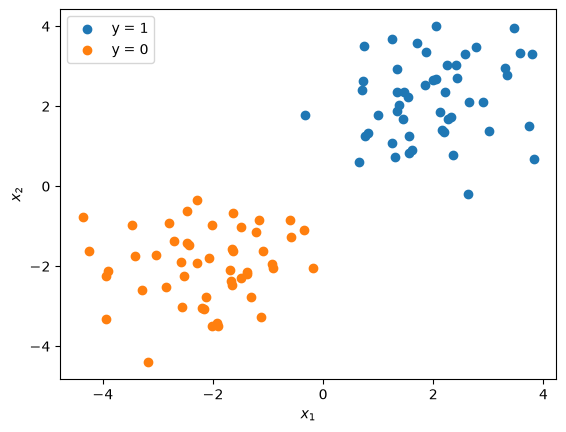

In [3]:
def make_two_clusters(n_per_class=50, cluster_std=1.0, seed=0):
    rng = np.random.default_rng(seed)
    X_pos = rng.normal(loc=2.0, scale=cluster_std, size=(n_per_class, 2))
    X_neg = rng.normal(loc=-2.0, scale=cluster_std, size=(n_per_class, 2))
    X = np.vstack([X_pos, X_neg])
    y = np.concatenate([np.ones(n_per_class), np.zeros(n_per_class)]).reshape(-1, 1)
    return X, y


X, y = make_two_clusters()

plt.scatter(X[y[:, 0] == 1, 0], X[y[:, 0] == 1, 1], label="y = 1")
plt.scatter(X[y[:, 0] == 0, 0], X[y[:, 0] == 0, 1], label="y = 0")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.legend()
plt.show()

The functions are written in the order backpropagation visits them: the loss first, the linear function last.

The cell of each exercise ends with a call that checks it. For a backward function, the check works as follows: the output of the forward function is reduced to a scalar by multiplying it elementwise with a fixed random array `g` and summing. The same `g` is passed to the backward function as the upstream gradient. By the chain rule, the result of the backward function must equal the numerical gradient of that scalar.

### Exercise 1.1: `mse`

In [4]:
def mse_forward(pred, target):
    """Mean squared error over all elements of pred and target.

    Returns (loss, cache), where loss is a scalar.
    """
    return np.mean((pred - target) ** 2), 2 * (pred - target) / pred.size


def mse_backward(cache):
    """Gradient of the loss with respect to pred.

    The loss is the last function of the chain, so there is no upstream gradient.
    """
    return cache  

checks.mse(mse_forward, mse_backward)

mse: all checks passed


### Exercise 1.2: `sigmoid`

In [5]:
def sigmoid_forward(z):
    """Elementwise sigmoid. Returns (a, cache)."""
    res =  (1 + np.exp(-z)) ** -1
    return res, res * (1 - res)


def sigmoid_backward(grad_a, cache):
    """Given the gradient of the loss with respect to a, return the gradient with respect to z.

    The derivative of the sigmoid was derived in Lab 4.
    """
    return grad_a * cache

checks.sigmoid(sigmoid_forward, sigmoid_backward)

sigmoid: all checks passed


### Exercise 1.3: `linear`

This function has three inputs, so its backward returns three gradients.

In [6]:
def linear_forward(x, W, b):
    """Affine map z = x @ W.T + b.

    x has shape (N, in), W has shape (out, in) and b has shape (out,).
    Returns (z, cache), with z of shape (N, out).
    """
    return x @ W.T + b, (x, W)


def linear_backward(grad_z, cache):
    """Gradients of the loss with respect to the inputs of linear_forward.

    grad_z has shape (N, out) and is the gradient of the loss with respect to z.
    Returns (dx, dW, db), each with the shape of the quantity it is the gradient of.
    """
    x, W = cache
    return grad_z @ W, grad_z.T @ x, grad_z.sum(0)

checks.linear(linear_forward, linear_backward)

linear: all checks passed


### Exercise 1.4: the whole neuron

Combine the six functions: run the three forward functions, then the three backward functions, and return the loss and the gradients of the loss with respect to `W` and `b`.

In [7]:
def neuron_loss_and_grads(W, b, X, y):
    """Loss of the neuron on the batch (X, y), and its gradients with respect to W and b.

    Returns (loss, dW, db). Uses only the six functions defined above.
    """
    X, cache_lin = linear_forward(X,W,b)
    X, cache_sig = sigmoid_forward(X)
    l, cache_los = mse_forward(X,y)
    grad_los = mse_backward(cache_los)
    grad_sig = sigmoid_backward(grad_los, cache_sig)
    _, dW, db = linear_backward(grad_sig, cache_lin)
    return l, dW, db

checks.neuron_loss_and_grads(neuron_loss_and_grads, X, y)

neuron_loss_and_grads: all checks passed


### Exercise 1.5: training loop

Train the neuron with full-batch gradient descent, using `neuron_loss_and_grads` for the gradients. The initial parameters are passed in and must not be modified.

In [8]:
W0 = np.zeros((1, 2))
b0 = np.zeros(1)
LR = 1.0
N_STEPS = 200


def train_neuron(X, y, W0, b0, lr, n_steps):
    """Full-batch gradient descent on the neuron, starting from W0 and b0.

    Returns (W, b, losses), where losses[i] is the loss at step i, before the update of that step.
    W0 and b0 must be left unchanged.
    """
    W = W0.copy()
    b = b0.copy()
    losses = []
    for k in range(n_steps):
        l, dW, db = neuron_loss_and_grads(W, b, X, y)
        losses.append(l)
        W -= lr * dW
        b -= lr * db
    return W, b, losses
checks.train_neuron(train_neuron, X, y, W0, b0, LR, N_STEPS)
W, b, losses_neuron = train_neuron(X, y, W0, b0, LR, N_STEPS)

train_neuron: all checks passed


### Exercise 1.6: results

Plot the loss against the step number, with axis labels.

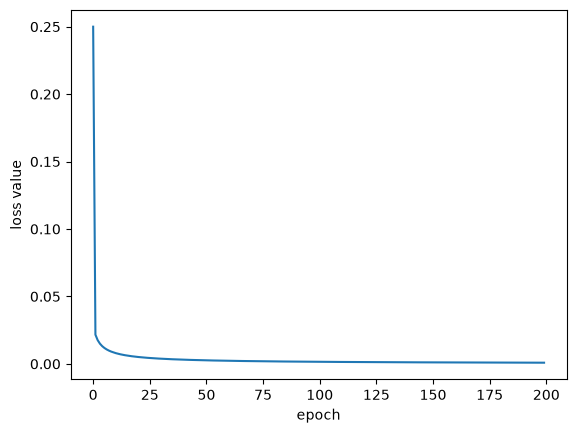

In [9]:
plt.plot(losses_neuron)
plt.xlabel("epoch")
plt.ylabel("loss value")
plt.show()

The cell below defines `plot_soft_decision_region`, which draws the output of a model over the input plane as a colour map, with the data points on top. The colour is the output itself, between 0 and 1, so the plot shows how the output changes across the plane. The black line marks the points where the output equals 0.5, the decision boundary.

The function takes `predict`, a function that maps an array of shape `(M, 2)` to outputs of shape `(M, 1)`. It can also draw into an existing matplotlib axis, passed as `ax`, to place several plots in one figure. The plot extends beyond the data by a fraction `margin` of its range. Here it is used on the trained neuron, and it is used again in the following parts.

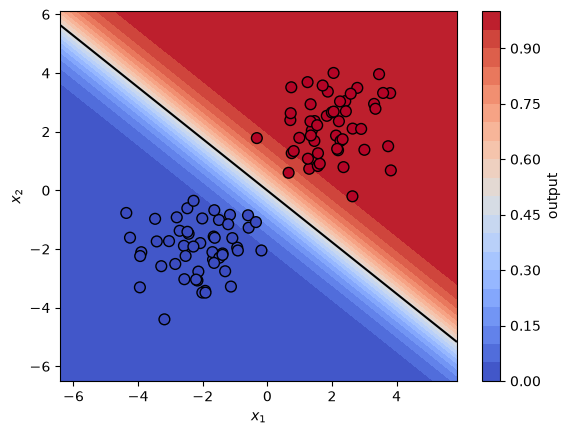

In [10]:
def plot_soft_decision_region(predict, X, y, ax=None, title=None, margin=0.25):
    show = ax is None
    if show:
        _, ax = plt.subplots()
    pad = margin * (X.max(axis=0) - X.min(axis=0))
    xs = np.linspace(X[:, 0].min() - pad[0], X[:, 0].max() + pad[0], 200)
    ys = np.linspace(X[:, 1].min() - pad[1], X[:, 1].max() + pad[1], 200)
    gx, gy = np.meshgrid(xs, ys)
    grid = np.column_stack([gx.ravel(), gy.ravel()])
    out = np.asarray(predict(grid)).reshape(gx.shape)
    filled = ax.contourf(gx, gy, out, levels=np.linspace(0, 1, 21), cmap="coolwarm", vmin=0, vmax=1)
    if out.min() < 0.5 < out.max():
        ax.contour(gx, gy, out, levels=[0.5], colors="k")
    ax.scatter(X[:, 0], X[:, 1], c=y[:, 0], cmap="coolwarm", vmin=0, vmax=1, edgecolors="k", s=60)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    if title is not None:
        ax.set_title(title)
    plt.colorbar(filled, ax=ax, label="output")
    if show:
        plt.show()


def predict_neuron(x):
    return sigmoid_forward(linear_forward(x, W, b)[0])[0]


plot_soft_decision_region(predict_neuron, X, y)

## Part 2: Modules

In Part 1, the caller kept every cache and called the backward functions in the right order. A **module** takes over both tasks: it stores its own cache and exposes `forward` and `backward` as methods. A network then becomes a list of modules.

The plumbing is provided in `minitorch/module.py`:

In [11]:
import inspect
from minitorch.module import Module, Parameter

print(inspect.getsource(Parameter))
print(inspect.getsource(Module))

class Parameter:
    """A learnable array together with its gradient.

    data: the current values, a NumPy array.
    grad: the gradient of the loss with respect to data, an array of the same shape.
          backward fills it in and the optimizer reads it.
    """

    def __init__(self, data):
        self.data = data
        self.grad = np.zeros_like(data)
        
    def __getattr__(self, name):
        return getattr(self.data, name)

class Module:
    """Base class of every building block of a network.

    A module implements two methods:

    forward(x)         computes the output and saves what backward will need.
    backward(grad)     receives the gradient of the loss with respect to the module's output.
                       It adds the gradients of the module's parameters to their .grad
                       and returns the gradient with respect to the module's input.

    Calling a module, as in model(x), runs forward.
    """

    def __call__(self, *args):
        

- `Parameter` pairs a value with its gradient, so an optimizer receives one list of objects.
- `Module.__call__` makes `model(x)` mean `model.forward(x)`.
- `parameters()` returns the module's `Parameter` objects as an explicit list. Modules without parameters return an empty list.
- `zero_grad()` sets the gradient of every parameter to zero. It is needed because `backward` adds to `.grad` instead of replacing it.

Turning the functions of Part 1 into modules involves two changes:

1. The cache is saved on the module in `forward` and read in `backward`, instead of being returned by `forward` and passed to `backward`. The attribute plays the role of the cache of Part 1. Every module has a `cache` attribute, declared in `Module` and empty until `forward` fills it. What `forward` stores in it is up to the module.
2. Parameter gradients are accumulated with `+=` into `weight.grad` and `bias.grad`, instead of being returned. `backward` returns only the gradient with respect to the module's input, with the shape of that input.

The loss is a module as well, with one difference: its `backward()` takes no argument, because nothing comes after it. It returns the gradient with respect to the prediction.

The modules are implemented in the order of Part 1. Each class has a skeleton in the file named in its exercise, and each exercise is checked by running the matching tests with pytest. The tests compare the gradients computed by `backward` with `numerical_gradient` (through `check_module` and `check_loss` from `minitorch.utils`) and raise an `AssertionError` that names the first gradient that does not match.

### Exercise 2.1: `MSELoss`

Implement `MSELoss` in `minitorch/loss.py`, then test it with `python -m pytest tests/test_loss.py -k mse -q`.

### Exercise 2.2: `Sigmoid`

Implement `Sigmoid` in `minitorch/layer.py`, then test it with `python -m pytest tests/test_layer.py -k sigmoid -q`.

### Exercise 2.3: `Linear`

Implement `Linear(in_features, out_features)` in `minitorch/layer.py`. Its forward computes $\mathbf{Z} = \mathbf{X}\mathbf{W}^\top + \mathbf{b}$. Its parameters are `weight` with shape `(out_features, in_features)` and `bias` with shape `(out_features,)`, both `Parameter` objects. `Linear` accepts 2D inputs only.

The tests also verify that `backward` accumulates into `.grad`.

You know the drill, test it with `python -m pytest tests/test_layer.py -k linear -q`

## Part 3: Chaining modules

`Sequential` holds a list of modules and applies them in order. Its `forward` and `parameters()` are provided in `minitorch/layer.py`. `backward` is written in this part.

### Exercise 3.1: `Sequential.backward`

Implement `Sequential.backward` in `minitorch/layer.py`. It receives the gradient with respect to the output of the model and returns the gradient with respect to its input.

The tests for this exercise compare the gradients obtained from `loss_fn.backward()` followed by `model.backward(...)` with the numerical gradient of the loss with respect to the input and to every parameter of the model (`check_model` in `minitorch.utils`). The tests of Part 2 check each module in isolation. These check how the modules are connected.

Again `python -m pytest tests/test_layer.py -k sequential -q`

## Part 4: The optimizer

Training moves every parameter of the network against its gradient. The optimizer collects the parameters of the network and applies this update to all of them, so the training code does not depend on what the network contains. It does not compute gradients: it uses the ones that `backward` has left in the `.grad` of each parameter.

`SGD`, in `minitorch/optim.py`, receives the list returned by `model.parameters()`. This list holds the `Parameter` objects used by the layers, not copies, so an update made by the optimizer is seen by the next forward pass. `SGD.zero_grad()` is provided and does the same as `Module.zero_grad()`.

### Exercise 4.1: `SGD.step`

Implement `SGD.step` in `minitorch/optim.py`, and the final one `python -m pytest tests/test_optim.py -q`.

## Part 5: Training a network on XOR

The XOR function takes the value 1 when exactly one of its two inputs is 1. Its two classes cannot be separated by a line, so a single neuron cannot fit it, as seen in the course. The network used here has a hidden layer of 2 sigmoid units followed by an output layer of 1 sigmoid unit (the input layer, whose size is fixed by the data, is not counted).

Training a network uses all the pieces written in this lab. At every step the gradients are zeroed, the forward pass and the loss are computed, the backward pass goes through the loss and then through the model, and the optimizer updates the parameters. The `train` function below does this on the whole dataset, with one step per epoch, and returns the loss at every epoch.

In [12]:
def train(model, loss_fn, optimizer, X, y, n_epochs):
    losses = []
    for _ in range(n_epochs):
        optimizer.zero_grad()                  # reset the gradients left by the previous step
        loss = loss_fn(model(X), y)            # forward pass and loss
        model.backward(loss_fn.backward())     # backward pass, from the loss to the input
        optimizer.step()                       # update the parameters
        losses.append(loss)
    return losses

The cell below checks the library on the neuron of Part 1. It trains `Sequential(Linear(2, 1), Sigmoid())` with `train`, from the same initial parameters. Both implementations do the same operations, so the loss curve and the final parameters must match those of Part 1.

In [13]:
checks.modules_match_functions(train, X, y, W0, b0, LR, N_STEPS, expected=(W, b, losses_neuron))

modules match the Part 1 functions: all checks passed


In [14]:
X_xor = np.array([[0.0, 0.0], [0.0, 1.0], [1.0, 0.0], [1.0, 1.0]])
y_xor = np.array([[0.0], [1.0], [1.0], [0.0]])

SEED = 4
XOR_LR = 1.0
XOR_STEPS = 5000

### Exercise 5.1: train the network

Build the network `Sequential(Linear(2, 2), Sigmoid(), Linear(2, 1), Sigmoid())` after calling `np.random.seed(SEED)`, and train it on the XOR data with `MSELoss`, `SGD` (learning rate `XOR_LR`) and `train`, for `XOR_STEPS` epochs. Store the model in `model_xor` and the loss at every epoch in `losses_xor`.

In [15]:
np.random.seed(SEED)
model_xor = Sequential(Linear(2, 2), Sigmoid(), Linear(2, 1), Sigmoid())
losses_xor = train(model_xor, minitorch.loss.MSELoss(), minitorch.optim.SGD(model_xor.parameters(), XOR_LR), X_xor, y_xor, XOR_STEPS)
checks.xor_default_init(model_xor, losses_xor, X_xor, y_xor, XOR_STEPS)

default initialization: all checks passed


The cell below plots the loss, and the output of the trained network over the input square with `plot_soft_decision_region` from Part 1.

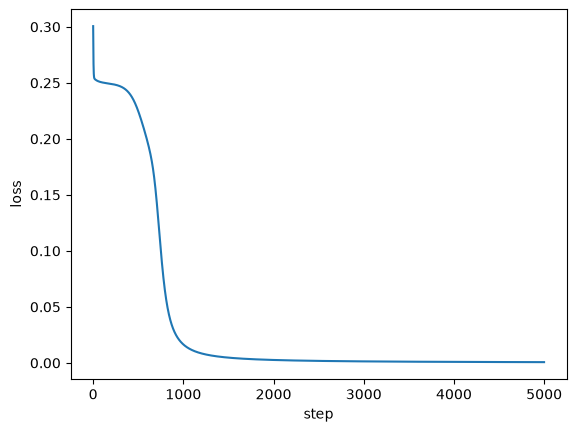

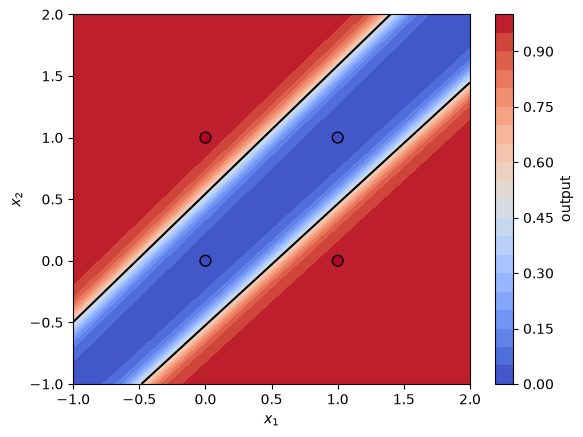

In [16]:
plt.plot(losses_xor)
plt.xlabel("step")
plt.ylabel("loss")
plt.show()

plot_soft_decision_region(model_xor, X_xor, y_xor, margin=1.0)

### Exercise 5.2: hidden neurons and seeds

A run **converges** when, after training, the output is above 0.5 for both inputs whose target is 1 and below 0.5 for both inputs whose target is 0. The cell below defines `has_converged`, `train_xor`, which repeats Exercise 5.1 for a given number of hidden neurons and seed (the learning rate is `XOR_LR`), and `convergence_rate`, the fraction of the seeds $0, 1, \dots, n_{seeds} - 1$ for which training converges. Each call of `convergence_rate` trains `n_seeds` networks, so use few seeds while exploring.

In [17]:
def has_converged(model):
    pred = model(X_xor)
    return bool(np.all((pred > 0.5) == (y_xor > 0.5)))


def train_xor(n_hidden, seed, n_steps=XOR_STEPS):
    np.random.seed(seed)
    model = Sequential(Linear(2, n_hidden), Sigmoid(), Linear(n_hidden, 1), Sigmoid())
    train(model, MSELoss(), SGD(model.parameters(), lr=XOR_LR), X_xor, y_xor, n_steps)
    return model


def convergence_rate(n_hidden, n_seeds=10):
    return np.mean([has_converged(train_xor(n_hidden, seed)) for seed in range(n_seeds)])

Compute the convergence rate for several numbers of hidden neurons, and look at what happens for different seeds. Present the results as a table or a plot.

2 hidden neurons: 65% of the seeds converge
3 hidden neurons: 95% of the seeds converge
4 hidden neurons: 100% of the seeds converge
8 hidden neurons: 100% of the seeds converge
2 hidden neurons, seeds that fail: [0, 1, 2, 3, 10, 12, 17]


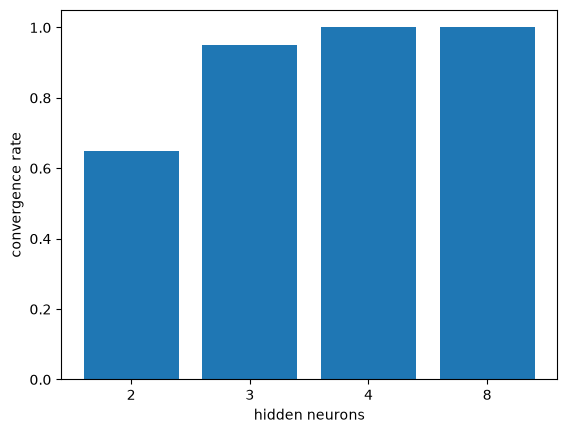

In [18]:
hidden_sizes = [2, 3, 4, 8]
rates = [convergence_rate(n, n_seeds=20) for n in hidden_sizes]
for n, r in zip(hidden_sizes, rates):
    print(f"{n} hidden neurons: {r:.0%} of the seeds converge")

failing = [s for s in range(20) if not has_converged(train_xor(2, s))]
print("2 hidden neurons, seeds that fail:", failing)

plt.bar([str(n) for n in hidden_sizes], rates)
plt.xlabel("hidden neurons")
plt.ylabel("convergence rate")
plt.show()

**Question 1.** Try other seeds and more hidden neurons. What do you observe?

**Answer.** With 2 hidden neurons only some seeds converge (about two thirds over seeds 0 to 19). With 3 almost all seeds converge, and with 4 or more all of them do. The runs that fail do not diverge: the loss flattens at a value above zero and the network gets 3 of the 4 points right. The loss surface has local minima, and which one gradient descent falls into depends on the initialization. More hidden neurons give the network more room, so a bad starting point is less likely to leave it stuck.

### Exercise 5.3: diagnosing a failed run

The function below, `plot_hidden_units`, applies `plot_soft_decision_region` to the inside of a network. It draws one panel per hidden neuron (the first `Linear` followed by the `Sigmoid`, so each panel is a single neuron like the one of Part 1, seen over the input plane), and a last panel with the output of the whole network.

In [19]:
def plot_hidden_units(model, X, y, max_units=4, margin=1.0, title=None):
    """Plot each hidden neuron of Sequential(Linear, Sigmoid, Linear, Sigmoid), then the network output."""
    hidden = Sequential(*model.layers[:2])      # first Linear + Sigmoid, sharing the layers of the model
    n_show = min(hidden.layers[0].weight.data.shape[0], max_units)
    fig, axes = plt.subplots(1, n_show + 1, figsize=(4.5 * (n_show + 1), 4))
    for k in range(n_show):
        plot_soft_decision_region(lambda x, k=k: hidden(x)[:, [k]], X, y, ax=axes[k],
                                  title=f"hidden neuron {k + 1}", margin=margin)
    plot_soft_decision_region(model, X, y, ax=axes[-1], title="network output", margin=margin)
    if title is not None:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()

Find a seed for which training with 2 hidden neurons does not converge. Use `plot_hidden_units` to look at what this network has learned, and do the same for a network trained with the same settings that did converge.

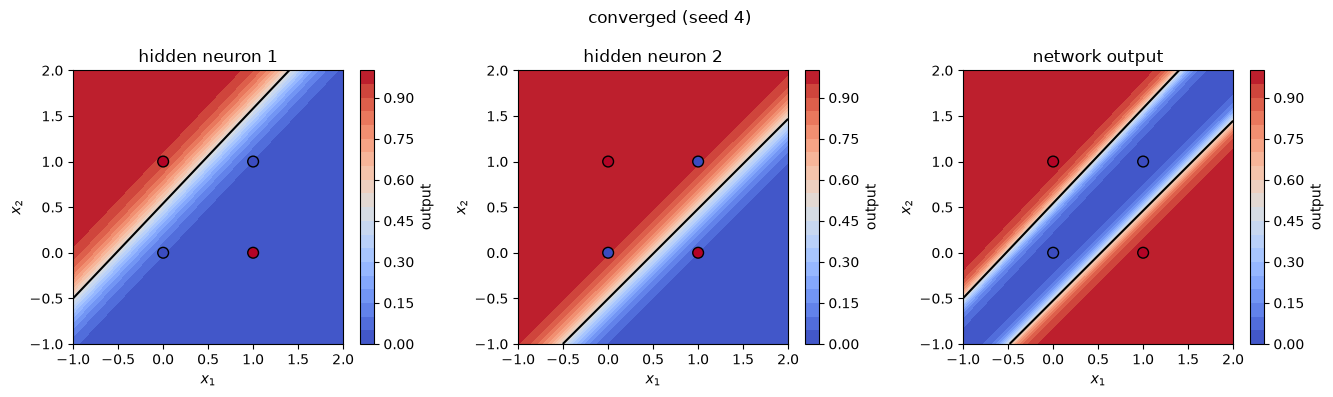

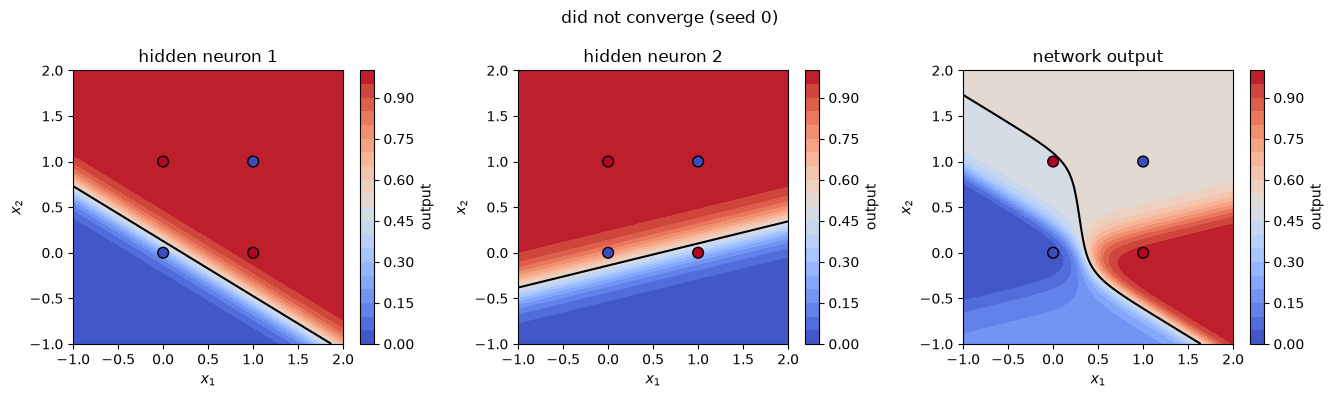

In [20]:
seed_fail = next(s for s in range(20) if not has_converged(train_xor(2, s)))
seed_ok = next(s for s in range(20) if has_converged(train_xor(2, s)))

plot_hidden_units(train_xor(2, seed_ok), X_xor, y_xor, title=f"converged (seed {seed_ok})")
plot_hidden_units(train_xor(2, seed_fail), X_xor, y_xor, title=f"did not converge (seed {seed_fail})")

**Question 2.** Using the plots, what went wrong in the network that did not converge?

**Answer.** The failed network got stuck in a local minimum with 3 out of 4 predictoins correct. In order to get to an optimal solution, it would need to go through a configuration where only two outputs are correct. Therefor, the gradient prevents it from finding an optimal solution.

## Part 6: Common issues

Training can go wrong without any error message. This part looks at two common causes.

### Exercise 6.1: initialization

In Lab 3, the weights of the perceptron started at zero and training worked.

**(a) All zeros.** The cell below builds the XOR network of Part 5 with all of its weights and biases set to zero.

In [21]:
np.random.seed(SEED)
model_zero = Sequential(Linear(2, 2), Sigmoid(), Linear(2, 1), Sigmoid())
for p in model_zero.parameters():
    p.data[...] = 0

Train it as in Exercise 5.1, with the same settings, and store the loss at every epoch in `losses_zero`. Then look at the loss, the output of the network and the gradients of its parameters.

zero initialization: all checks passed


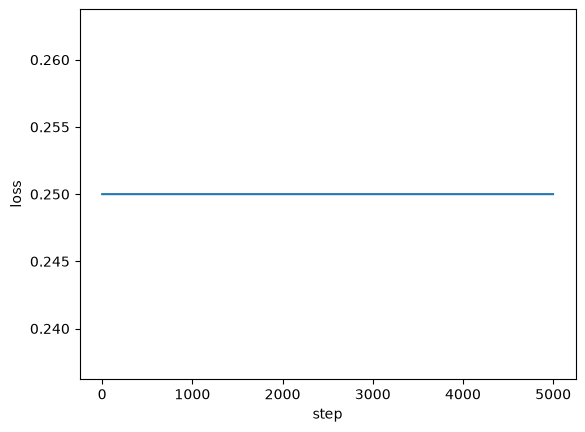

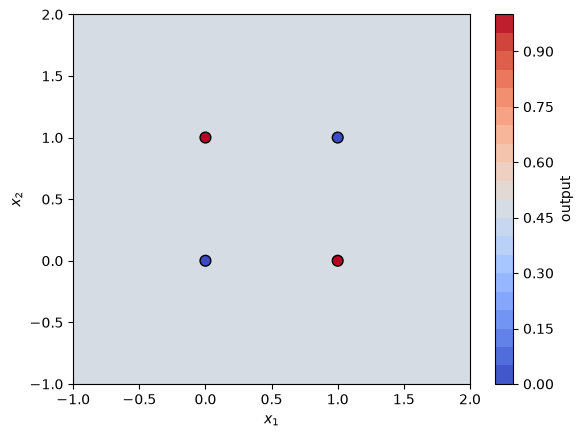

In [22]:
losses_zero = train(model_zero, minitorch.loss.MSELoss(), minitorch.optim.SGD(model_zero.parameters(), XOR_LR), X_xor, y_xor, XOR_STEPS)

checks.xor_zero_init(model_zero, losses_zero, X_xor, y_xor, XOR_STEPS)

plt.plot(losses_zero)
plt.xlabel("step")
plt.ylabel("loss")
plt.show()

plot_soft_decision_region(model_zero, X_xor, y_xor, margin=1.0)

In [23]:
for name, p in zip(["W1", "b1", "W2", "b2"], model_zero.parameters()):
    print(name, "grad:\n", p.grad, "\n")

W1 grad:
 [[0. 0.]
 [0. 0.]] 

b1 grad:
 [0. 0.] 

W2 grad:
 [[0. 0.]] 

b2 grad:
 [0.] 



**Question 3.** What do you observe, and why does training fail when all the weights are initialized to zero?

**Answer.** The loss stays at 0.25 and the output is 0.5 everywhere: nothing moves, because every gradient is exactly zero. The hidden layer gets no gradient because the backward pass multiplies by the output weights, which are zero. The output layer gets none because the output is the same for all four inputs, the targets are balanced (two 0s and two 1s), and the gradients cancel out over the batch. Zero is a stationary point of the loss for this problem. (In Lab 3 the perceptron had a single layer, so no gradient had to pass through zero weights.)

**(b) A constant.** Zero is a special value, so try another one. The cell below builds the same network with every weight and bias set to 0.5.

In [24]:
np.random.seed(SEED)
model_const = Sequential(Linear(2, 2), Sigmoid(), Linear(2, 1), Sigmoid())
for p in model_const.parameters():
    p.data[...] = 0.5

Train it as in Exercise 5.1, with the same settings, and store the loss at every epoch in `losses_const`. Then look at the loss, the output of the network and the gradients of its parameters.

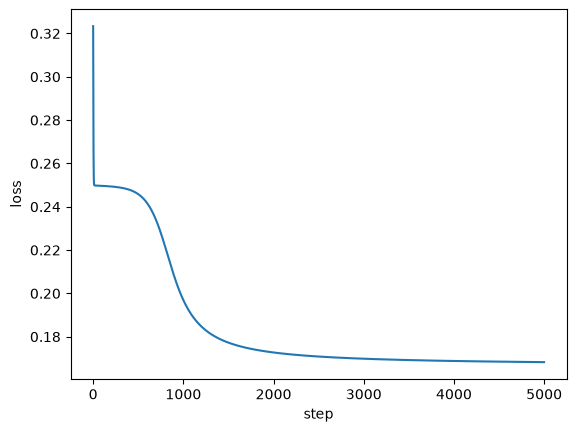

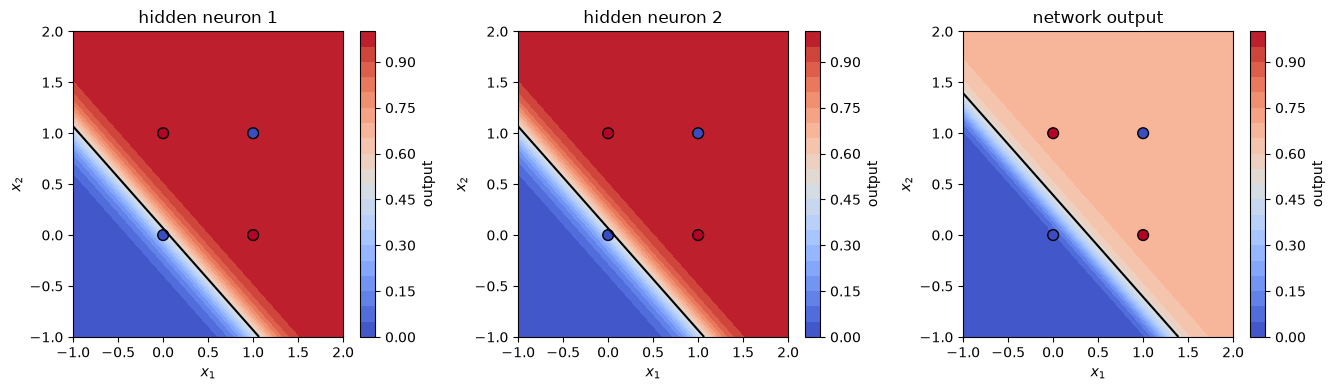

In [25]:
losses_const = train(model_const, minitorch.loss.MSELoss(), minitorch.optim.SGD(model_const.parameters(), XOR_LR), X_xor, y_xor, XOR_STEPS)

plt.plot(losses_const)
plt.xlabel("step")
plt.ylabel("loss")
plt.show()

plot_hidden_units(model_const, X_xor, y_xor)

In [26]:
layer1, layer2 = model_const.layers[0], model_const.layers[2]
print("W1:\n", layer1.weight.data)
print("W1 grad:\n", layer1.weight.grad)
print("W2:\n", layer2.weight.data)
print("W2 grad:\n", layer2.weight.grad)

W1:
 [[6.42727153 6.42727153]
 [6.42727153 6.42727153]]
W1 grad:
 [[-0.00029301 -0.00029301]
 [-0.00029301 -0.00029301]]
W2:
 [[3.190957 3.190957]]
W2 grad:
 [[-9.77794938e-05 -9.77794938e-05]]


**Question 4.** What do you observe, and why does training fail here too? What would you change in the initialization?

**Answer.** The loss now moves, but the network still ends up misclassifying one point. The two hidden neurons have exactly the same weights, and so exactly the same gradients, at every step: their rows of `W1` and the two entries of `W2` stay equal forever. The hidden layer is therefore a single neuron copied twice, and a single neuron cannot solve XOR. This is the symmetry between the neurons of a layer: any identical initialization (zero included) never breaks it. The fix is to initialize the weights randomly, so the neurons start different and receive different gradients. How to choose the scale of this randomness is the topic of Lab 6.

### Exercise 6.2: the order of calls

Every module keeps a single cache, and `backward` adds to `.grad`. The training loop is therefore correct only with its calls in the order of `train`: zero the gradients, forward pass, loss, backward pass, update. Two ways of breaking this order raise no error at all:

- `train_with_extra_forward` runs a forward pass on other data (`x_val`) between the loss and the backward pass. This happens, for example, when the validation loss is computed inside the training loop.
- `train_without_zero_grad` never calls `optimizer.zero_grad()`.

The cell below trains the network of Exercise 5.1 with each of them, with the same settings, and plots the three loss curves together. Diagnose what happens in each case.

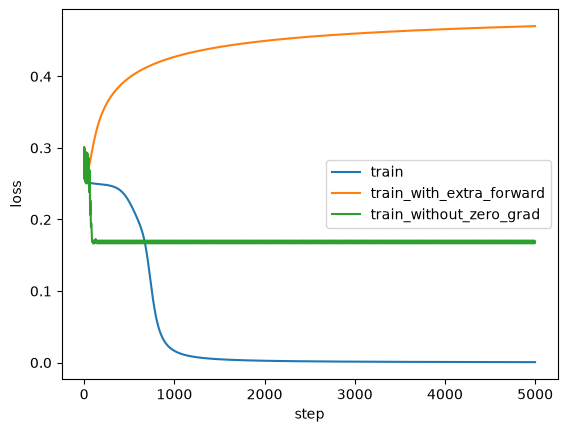

In [27]:
x_val = np.random.default_rng(7).uniform(-0.5, 1.5, size=(4, 2))


def train_with_extra_forward(model, loss_fn, optimizer, X, y, n_epochs):
    losses = []
    for _ in range(n_epochs):
        optimizer.zero_grad()
        loss = loss_fn(model(X), y)
        model(x_val)                           # forward pass on other data
        model.backward(loss_fn.backward())
        optimizer.step()
        losses.append(loss)
    return losses


def train_without_zero_grad(model, loss_fn, optimizer, X, y, n_epochs):
    losses = []
    for _ in range(n_epochs):
        loss = loss_fn(model(X), y)            # no optimizer.zero_grad()
        model.backward(loss_fn.backward())
        optimizer.step()
        losses.append(loss)
    return losses


def train_variant(train_fn):
    np.random.seed(SEED)
    model = Sequential(Linear(2, 2), Sigmoid(), Linear(2, 1), Sigmoid())
    return train_fn(model, MSELoss(), SGD(model.parameters(), XOR_LR), X_xor, y_xor, XOR_STEPS)


plt.plot(train_variant(train), label="train")
plt.plot(train_variant(train_with_extra_forward), label="train_with_extra_forward")
plt.plot(train_variant(train_without_zero_grad), label="train_without_zero_grad")
plt.xlabel("step")
plt.ylabel("loss")
plt.legend()
plt.show()

**Question 5.** What happens when a forward pass on other data comes before the backward pass, and why? Would it matter if the extra forward pass used the same inputs as the training step?

**Answer.** The loss does not decrease, and ends up worse than it started. The extra forward pass overwrites the caches of every module with the values computed for `x_val`, so `backward` computes the gradient of the loss as if the network had been fed `x_val`, combined with the loss gradient of the training batch. No error is raised because `x_val` has the same number of rows as the training data, so all the shapes match. If the extra forward pass used the same inputs it would not matter (the caches would hold the same values), but it would waste computation, and it is the same mistake as soon as the inputs differ.

**Question 6.** What happens when the gradients are not zeroed between steps, and why?

**Answer.** `backward` adds to `.grad`, so without `zero_grad` the gradient used at step $k$ is the sum of the gradients of all the previous steps. Old directions keep being applied: the effective step size grows, the updates overshoot, and the loss does not go down to zero (here the network stays stuck on a wrong solution).

> **Note.** `backward` also relies on the cache of the `forward` call that precedes it, so calling it before any `forward` fails. Deep learning libraries guard against all these cases. In minitorch, guards would require extra machinery, so they are left out to keep the code simple: it is up to the code that trains the model to call `forward` and `backward` in the right order.

## Running the tests

Run all the tests of the modules, the loss and the optimizer together from a terminal, at the root of the project:

```
python -m pytest tests/test_layer.py tests/test_loss.py tests/test_optim.py -q
```